# IND320 - Project work, part 3 - Data quality

## Link to Github: https://github.com/Rita-HT/IND320-reservoir
## Link to Streamlit: https://ind320reservoir.streamlit.app/
## Screencast uploaded on Github

## Imports libaries and load NVE shapefiles 

The following code imports the necessary libraries for the project and loads the downloaded shapefiles from the Norwegian Water Resources and Energy Directorate (NVE) through NVE Atlas

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Loadthe five regions data from NVE and convert the coordinate system 
regions = gpd.read_file("NVE_Region/NVE_Region.shp", encoding="utf-8").to_crs(4326)

#Shows the coordinate system and column names
print("Rows, columns", regions.shape)
print("Coordinate system", regions.crs)
print("Name of columns", regions.columns.tolist())
print("Missing values")
print(regions.isna().sum())

# Shows the first five rows
regions.head()

Rows, columns (5, 8)
Coordinate system EPSG:4326
Name of columns ['OBJECTID', 'REGION', 'REGIONNAVN', 'POSTNUMMER', 'POSTSTED', 'BESØKSADR', 'ADRESSE', 'geometry']
Missing values
OBJECTID      0
REGION        0
REGIONNAVN    0
POSTNUMMER    0
POSTSTED      0
BESØKSADR     0
ADRESSE       0
geometry      0
dtype: int64


,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESØKSADR,ADRESSE,geometry
0,1.0,RV,Region Vest,6801,Førde,Naustdalsveien 1B,Postboks 53,"POLYGON ((9.06206 62.37261, 9.03652 62.36454, ..."
1,2.0,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9,"POLYGON ((12.54589 66.59724, 12.57049 66.58119..."
2,3.0,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54,"POLYGON ((31.10426 69.97927, 30.88899 69.84112..."
3,4.0,RØ,Region Øst,2307,Hamar,Vangsvegen 73,Postboks 4223,"POLYGON ((10.56069 60.16556, 10.55883 60.16561..."
4,5.0,RS,Region Sør,3103,Tønsberg,Anton Jenssens gate 7,Postboks 2124,"POLYGON ((10.56069 60.16556, 10.56435 60.1611,..."


The data contains five regions with the coordinate reference system EPSG:4326, which represents longitude and latitude. The dataset includes the following columns: OBJECTID, REGION, REGIONNAVN, POSTNUMMER, POSTSTED, BESØKSADR, ADRESSE and geometry. By using encoding="utf-8", the Norwegian letters ø, æ and å can be displayed correctly. According to the assignment, East is split into RS + RØ, and North is split into RM + RN, however West (RV) is not mentioned in the assignment.

# Randomly sampled 1000 locations in each region to use for weather data download

East consists of RS and RØ, while North consists of RM and RN. West (RV) is treated as a separate region We generate 1000 random points for each of the five regions, save their coordinates, and visualize them to make sure they are located within the correct geographical areas.

In [6]:
# Define which NVE regions belong to each area -  East is split into RS + RØ, North is split into RM + RN,  West (RV) is not mentioned in the assignment.
NVE_regions = {"East": ["RS", "RØ"], "North": ["RM", "RN"], "West": ["RV"], "Mid": ["RM"]}

import numpy as np
import pandas as pd
import shapely
import matplotlib.pyplot as plt


# Generate random points inside a polygon
def sample_points_in(geom, n, random_generator):
    minx, miny, maxx, maxy = geom.bounds
    random_points = np.empty((0, 2))

    while len(random_points) < n:
        x = random_generator.uniform(minx, maxx, n * 5)
        y = random_generator.uniform(miny, maxy, n * 5)

        inside = shapely.contains_xy(geom, x, y)
        new_points = np.column_stack([x[inside], y[inside]])

        random_points = np.vstack([random_points, new_points])

    return random_points[:n]


# Set random seed
random_generator = np.random.default_rng(123)

frames = []

# Generate 2000 random points for each region
for region_name, region_codes in NVE_regions.items():

    # Select and merge the relevant regions
    geom = regions.loc[
        regions["REGION"].isin(region_codes), "geometry"
    ].union_all()

    # Generate random points inside the region
    random_points = sample_points_in(geom, 1000, random_generator)

    # Store the points
    frames.append(pd.DataFrame({
        "region": region_name,
        "lon": random_points[:, 0],
        "lat": random_points[:, 1]
    }))


# Combine all regions
all_locations = pd.concat(frames, ignore_index=True)

# Save coordinates
all_locations.to_csv("random_points.csv", index=False)


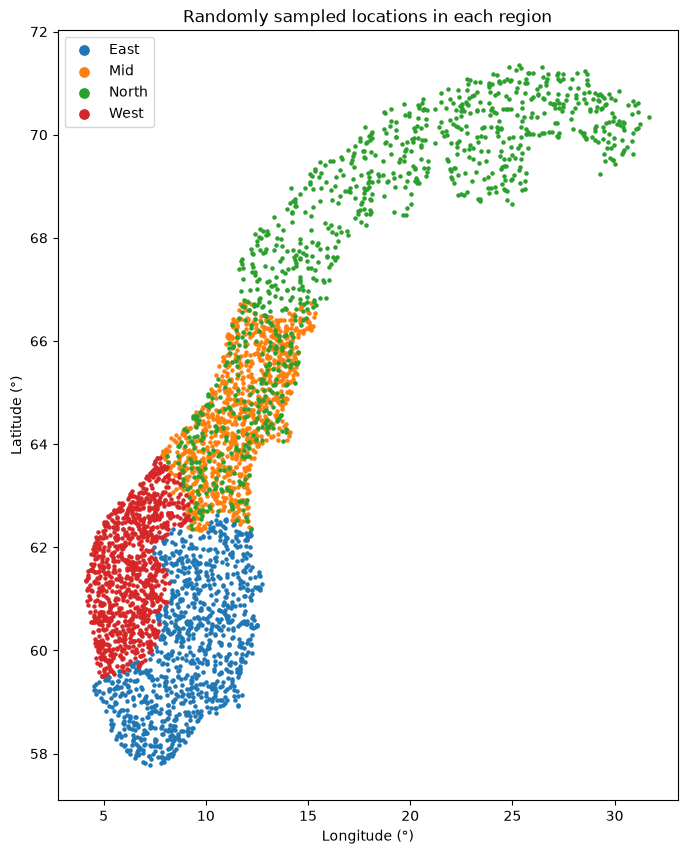

In [7]:
# Plot the generated points to check that they are inside the correct regions
fig, ax = plt.subplots(figsize=(8, 10))

for region_name, region_group in all_locations.groupby("region"):
    ax.scatter(
        region_group["lon"],
        region_group["lat"],
        s=5,
        label=region_name
    )

ax.set(xlabel="Longitude (°)", ylabel="Latitude (°)",
       title="Randomly sampled locations in each region")
ax.legend(markerscale=3)

plt.show()

In [8]:
# Count the number of points in each region
points_per_region = (
    all_locations.groupby("region")
    .size()
    .reset_index(name="Number of points")
)

# Add the corresponding NVE region codes
points_per_region["NVE regions"] = points_per_region["region"].map(
    lambda region: " + ".join(NVE_regions[region])
)

# Display the results
print("Number of randomly sampled points per region:")
display(points_per_region)

Number of randomly sampled points per region:


,region,Number of points,NVE regions
0,East,1000,RS + RØ
1,Mid,1000,RM
2,North,1000,RM + RN
3,West,1000,RV


## Plot and table output
The plot displays 1000 points across each of the four areas. All points are located within the correct geographical boundaries. The overlap between Mid and North is expected, as both regions include RM.

The table provides an overview of the 1000 points generated for each area and shows which NVE regions they belong to. The first 50 points from each area are also stored in a separate JSON file, which is used by the Streamlit application instead of a CSV file


## Download weather data (Open-Meteo, ERA5)

Hourly weather data is collected using the download_weather function, which connects to the Open-Meteo archive API. The function retrieves eight weather variables for a selected region and time period, using the first n_locations coordinates from that region. To manage the number of API requests, the locations are divided into groups of 25. If the API limit is reached (error 429), the code pauses before attempting the request again. Due to these restrictions, the number of locations is limited to 50 per region. Function is tested on a small dataset, and then used for NO3 in 2024

In [10]:
#Saved the first 50 points per region for the Streamlit app (JSON, not CSV)
all_locations.groupby("region").head(50).round(4).to_json(
"locations.json", orient="records")

In [11]:

import time
import requests

# Open-Meteo archive API
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

# Weather variables to download
HOURLY_VARS = [
    "temperature_2m",
    "precipitation",
    "rain",
    "snowfall",
    "wind_speed_10m",
    "relative_humidity_2m",
    "surface_pressure",
    "cloud_cover"
]


# Download hourly weather data for one region
def download_weather(region, start, end, locations, n_locations=50, batch_size=25):

    # Select locations within the region
    points = locations[locations["region"] == region].head(n_locations).reset_index(drop=True)

    frames = []

    # Download data in batches
    for i in range(0, len(points), batch_size):
        batch = points.iloc[i:i + batch_size]

        params = {
            "latitude": ",".join(f"{v:.4f}" for v in batch["lat"]),
            "longitude": ",".join(f"{v:.4f}" for v in batch["lon"]),
            "start_date": start,
            "end_date": end,
            "hourly": ",".join(HOURLY_VARS),
            "models": "era5"
        }

        # Retry if the API rate limit is reached
        for attempt in range(6):
            response = requests.get(ARCHIVE_URL, params=params, timeout=120)

            if response.status_code == 429:
                time.sleep(15 * 2 ** attempt)
                continue

            response.raise_for_status()
            break

        data = response.json()

        if isinstance(data, dict):
            data = [data]

        # Store weather data for each location
        for j, location in enumerate(data):
            df = pd.DataFrame(location["hourly"])
            df["time"] = pd.to_datetime(df["time"])
            df["location_id"] = i + j
            frames.append(df)

        time.sleep(1)

    # Combine all weather data
    return pd.concat(frames, ignore_index=True)


## Test - downloading hourly historical weather data (ERA5) 
All regions return a dataset with 840 rows and 10 columns, which is the expected result
7 × 24 × 5 = 840 rader og 10 columns pr region

In [13]:
# Download weather data for all regions
weather_data = {}

for region_name in all_locations["region"].unique():
    weather_data[region_name] = download_weather(
        region_name,
        "2024-01-01",
        "2024-01-07",
        all_locations,
        n_locations=5
    )

# Check the results
for region_name, data in weather_data.items():
    print(region_name, data.shape)

East (840, 10)
North (840, 10)
West (840, 10)
Mid (840, 10)


## Weather data for the analysis area
“Mid” region (RM) represents NO3 (Mid-Norway), since the assignment focuses on this price area. As the NVE regions do not follow the exact same boundaries as the electricity price areas, RM is used as the closest approximation. Weather data is collected for 50 locations throughout the region, covering all hours of 2024. The measurements are then combined by calculating an hourly average across all locations, resulting in a dataset called weather_mean. 

In [15]:
# Choose the region to analyse (Mid ≈ NO3)
ANALYSIS_REGION = "Mid"

# Download hourly weather data for 2024 for the chosen region
weather_raw = download_weather(ANALYSIS_REGION, "2024-01-01", "2024-12-31",
                               all_locations, n_locations=50)

# Average all locations for each hour
weather_mean = weather_raw.groupby("time")[HOURLY_VARS].mean()
print(weather_mean.shape)

(8784, 8)


The resulting dataset contains 8,784 rows and 8 columns, representing hourly average weather data for all 50 locations throughout 2024. This is the expected size, as 2024 is a leap year.

In the following code, dct_highpass removes slow changes in the data. Then, plot_spc_outliers calculates upper and lower limits using the median and MAD. These limits are used to identify values that are far from normal. Points outside the limits are marked as outliers. The cutoff is set to 10 cycles per year, with a 3-sigma limit.

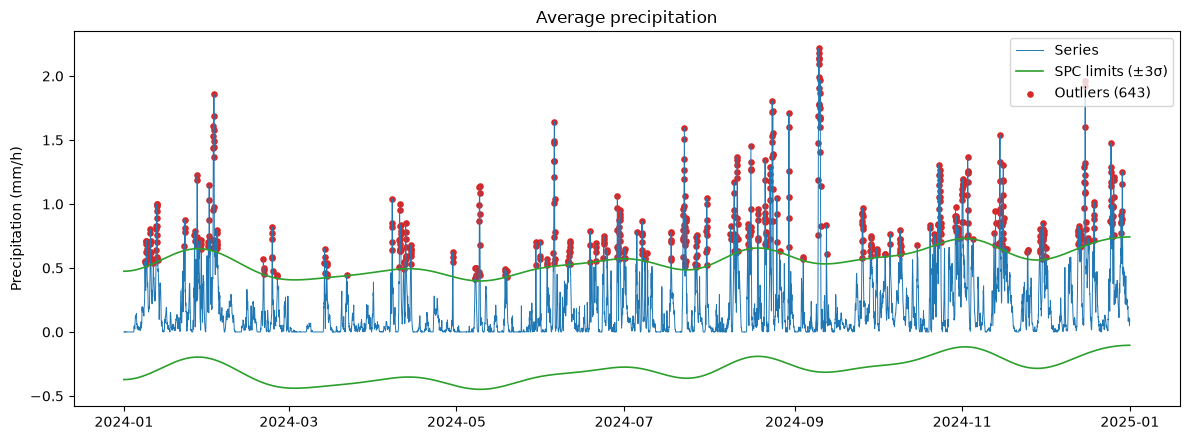

{'n_points': 8784, 'n_outliers': 643, 'share_outliers_%': np.float64(7.32), 'n_std': 3, 'cutoff_per_year': 10, 'median': -0.05863472760645172, 'robust_sigma': 0.14110610717080263, 'n_above': 643, 'n_below': 0}


,value,highpass
time,,
2024-09-09 20:00:00,2.216,2.046777
2024-09-09 19:00:00,2.180,2.010699
2024-09-09 21:00:00,2.138,1.968854
2024-09-09 22:00:00,2.132,1.962929
2024-09-09 23:00:00,2.092,1.923003
2024-09-10 00:00:00,1.992,1.823075
2024-09-10 07:00:00,1.966,1.797541
2024-12-15 18:00:00,1.962,1.652606
2024-12-15 19:00:00,1.920,1.610269


In [17]:

from scipy.fft import dct, idct


# Apply a DCT high-pass filter
def dct_highpass(series, cutoff_per_year=10.0, samples_per_year=8766):

    series = np.asarray(
        pd.Series(series).interpolate(limit_direction="both"),
        dtype=float
    )

    n = len(series)
    cutoff = int(round(cutoff_per_year * 2 * n / samples_per_year))
    cutoff = min(max(cutoff, 1), n)

    coefficients = dct(series, type=2, norm="ortho")
    coefficients[cutoff:] = 0

    lowpass = idct(coefficients, type=2, norm="ortho")
    highpass = series - lowpass

    return highpass, lowpass


# Detect outliers using SPC limits
def plot_spc_outliers(series, cutoff_per_year=10.0, n_std=3.0,
                      title="Average precipitation",
                      ylabel="Precipitation (mm/h)"):

    series = series.astype(float)
    highpass, lowpass = dct_highpass(series, cutoff_per_year)

    median = np.median(highpass)
    sigma = 1.4826 * np.median(np.abs(highpass - median))

    if sigma == 0:
        sigma = highpass.std()

    upper = lowpass + median + n_std * sigma
    lower = lowpass + median - n_std * sigma

    is_outlier = (
        (highpass > median + n_std * sigma) |
        (highpass < median - n_std * sigma)
    )

    # Plot the series and SPC limits
    fig, ax = plt.subplots(figsize=(12, 4.5))

    ax.plot(series.index, series.values,
            color="tab:blue", lw=0.7, label="Series")

    ax.plot(series.index, upper,
            color="tab:green", lw=1.2, label=f"SPC limits (±{n_std:g}σ)")

    ax.plot(series.index, lower, color="tab:green", lw=1.2)

    ax.scatter(series.index[is_outlier], series.values[is_outlier],
               color="tab:red", s=14, label=f"Outliers ({is_outlier.sum()})")

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper right")

    fig.tight_layout()

    # Store detected outliers
    outliers = pd.DataFrame({
        "value": series.values[is_outlier],
        "highpass": highpass[is_outlier]
    }, index=series.index[is_outlier])

    # Summarize the results
    summary = {
        "n_points": len(series),
        "n_outliers": int(is_outlier.sum()),
        "share_outliers_%": round(100 * is_outlier.mean(), 2),
        "n_std": n_std,
        "cutoff_per_year": cutoff_per_year,
        "median": float(median),
        "robust_sigma": float(sigma),
        "n_above": int((highpass > median + n_std * sigma).sum()),
        "n_below": int((highpass < median - n_std * sigma).sum())
    }

    return fig, summary, outliers


# Test the SPC function
fig, summary, outliers = plot_spc_outliers(
    weather_mean["precipitation"],
    cutoff_per_year=10,
    n_std=3
)

plt.show()

print(summary)

outliers.sort_values("value", ascending=False).head(10)


None of the 643 outliers fall below the lower limit. All of them are linked to higher precipitation values. This is expected, as rainfall cannot have negative values, and heavy rain usually occurs in short periods. The highest measurements were recorded on 9–10 September 2024, reaching approximately 2.2 mm/h. Another high value occurred on 15 December 2024.

## Comparing different SPC thresholds
The analysis is run again using 2, 3 and 4 sigma to compare how many outliers are detected with different limits. When the threshold is lower, more values are identified as outliers. A limit of 3 sigma is chosen as the standard setting because it helps identify unusual values without marking too many normal observations.

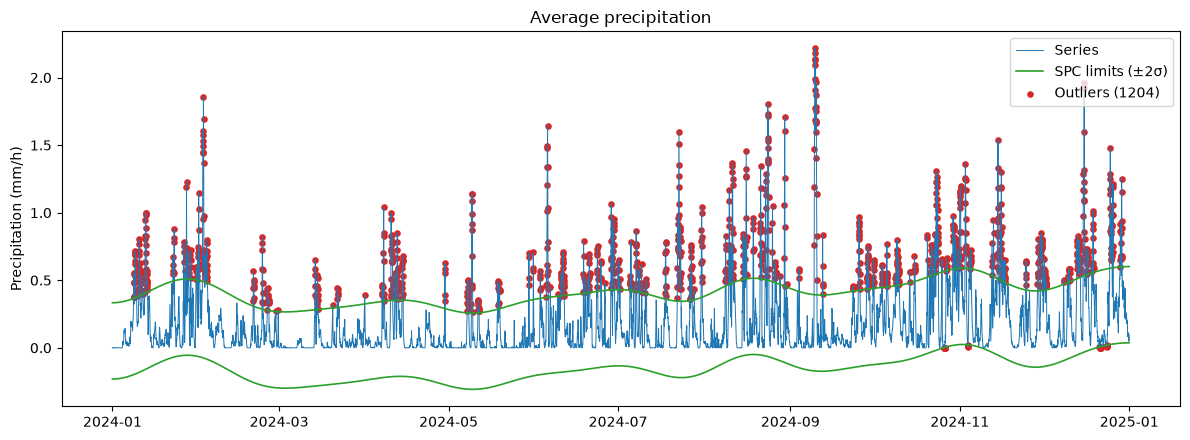

Threshold = 2: 1204 outliers (13.71 %)


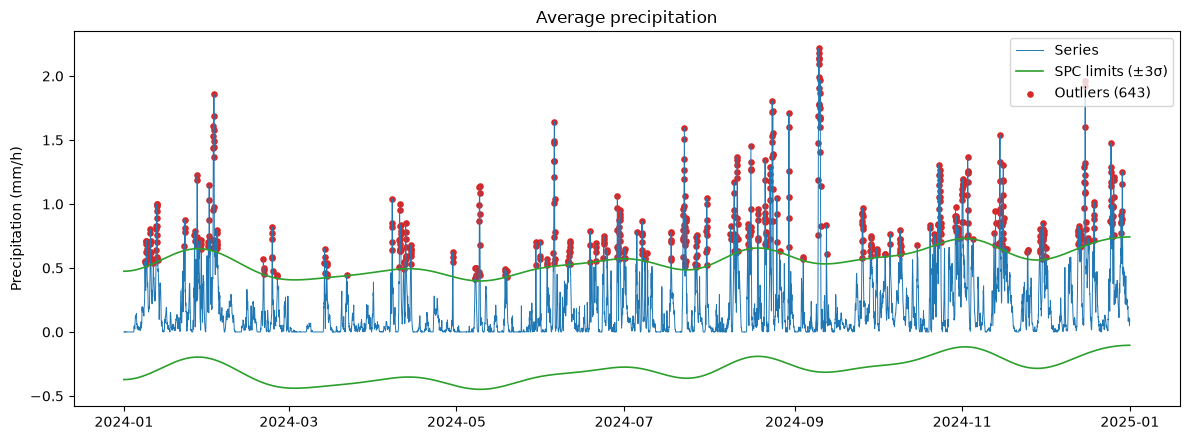

Threshold = 3: 643 outliers (7.32 %)


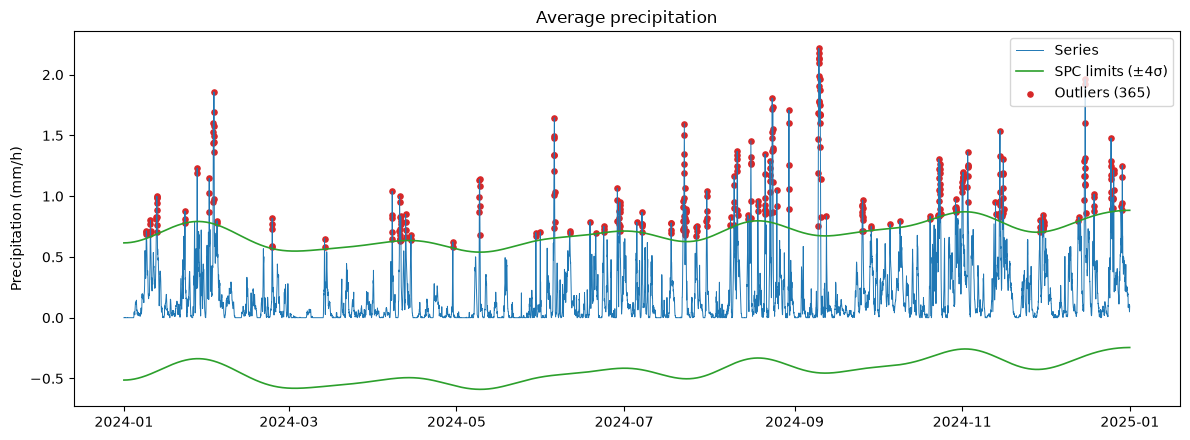

Threshold = 4: 365 outliers (4.16 %)


In [19]:
# Compare different SPC thresholds
for threshold in [2, 3, 4]:

    fig, results, outliers = plot_spc_outliers(
        weather_mean["precipitation"],
        cutoff_per_year=10,
        n_std=threshold
    )

    plt.show()

    print(
        f"Threshold = {threshold}: "
        f"{results['n_outliers']} outliers "
        f"({results['share_outliers_%']} %)"
    )

## Detecting anomalies using LOF
LOF is used to detect unusual temperature values in the dataset. First, the normal seasonal changes are removed using the same DCT filter as before. This prevents regular differences between summer and winter from being marked as anomalies. LOF then looks at how each value compares to nearby data points. The 1% most unusual values are marked as anomalies and shown in red in the plot. The table below also shows the values with the highest anomaly scores.

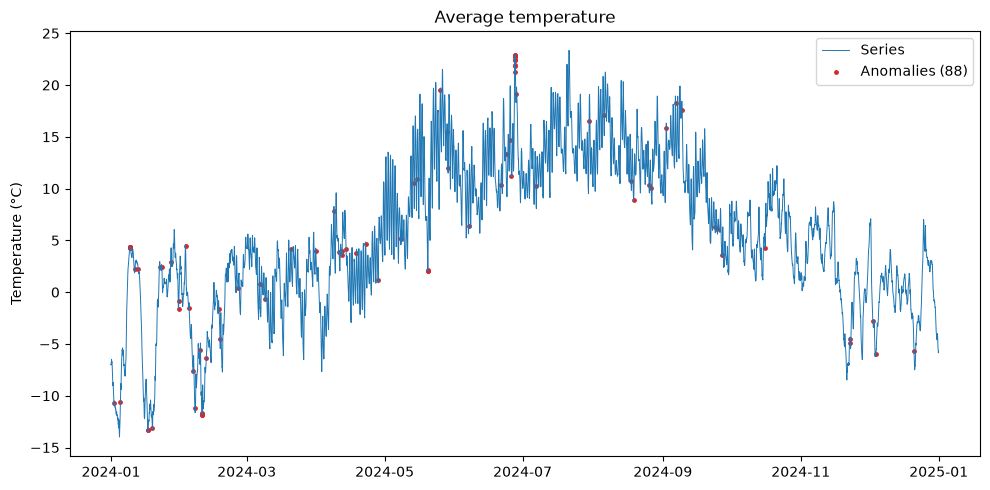

{'n_points': 8784, 'n_anomalies': 88, 'share_anomalies_%': np.float64(1.0), 'contamination': 0.01, 'n_neighbors': 15, 'cutoff_per_year': 8.0, 'max_anomaly_score': 4.0545267842336}


,value,highpass,anomaly_score
time,,,
2024-06-27 16:00:00,22.946,10.660757,4.054527
2024-06-27 17:00:00,22.856,10.564635,3.893002
2024-06-27 15:00:00,22.788,10.508864,3.799284
2024-06-27 14:00:00,22.664,10.390955,3.606198
2024-06-27 13:00:00,22.428,10.161030,3.272799
2024-06-27 18:00:00,22.408,10.110497,3.206753
2024-06-27 12:00:00,21.894,9.633088,3.014301
2024-06-27 19:00:00,21.824,9.520343,2.851001
2024-05-20 02:00:00,2.008,-10.181878,2.054421


In [21]:
from sklearn.neighbors import LocalOutlierFactor

# Detect anomalies using LOF
def plot_lof_anomalies(series, contamination=0.01, n_neighbors=15,
                       cutoff_per_year=8.0, title="Average temperature",
                       ylabel="Temperature (°C)"):

    # Prepare the data
    filtered_data = series.astype(float)
    highpass, _ = dct_highpass(filtered_data, cutoff_per_year)

    # Fit the LOF model
    lof_model = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )
    predictions = lof_model.fit_predict(highpass.reshape(-1, 1))

    # Identify anomalies and calculate scores
    is_anomaly = predictions == -1
    anomaly_scores = -lof_model.negative_outlier_factor_

    # Plot the results
    fig, axis = plt.subplots(figsize=(10, 5))
    axis.plot(
        filtered_data.index, filtered_data.values,
        color="tab:blue", lw=0.7, label="Series"
    )
    axis.scatter(
        filtered_data.index[is_anomaly],
        filtered_data.values[is_anomaly],
        color="tab:red", s=6,
        label=f"Anomalies ({is_anomaly.sum()})"
    )
    axis.set(title=title, ylabel=ylabel)
    axis.legend(loc="upper right")
    fig.tight_layout()

    # Store detected anomalies
    detected_anomalies = pd.DataFrame({
        "value": filtered_data.values[is_anomaly],
        "highpass": highpass[is_anomaly],
        "anomaly_score": anomaly_scores[is_anomaly]
    }, index=filtered_data.index[is_anomaly])

    # Summarize the results
    summary = {
        "n_points": len(filtered_data),
        "n_anomalies": int(is_anomaly.sum()),
        "share_anomalies_%": round(100 * is_anomaly.mean(), 2),
        "contamination": contamination,
        "n_neighbors": n_neighbors,
        "cutoff_per_year": cutoff_per_year,
        "max_anomaly_score": float(anomaly_scores.max())
    }

    return fig, summary, detected_anomalies


# Test the LOF function
fig, summary, detected_anomalies = plot_lof_anomalies(
    weather_mean["temperature_2m"]
)

plt.show()
print(summary)
detected_anomalies.sort_values(
    "anomaly_score", ascending=False
).head(10)

The most unusual temperature values were recorded on the afternoon of 27 June 2024, when the temperature was around 23 °C. This stands out from the nearby measurements. The remaining anomalies are mainly brief changes in temperature, which occur mostly during the winter and spring months.

## Magasindata
Weekly reservoir data for NO3 is retrieved from the NVE API and organised as a time series using the dates as the index. The dataset contains 1661 weekly observations, and the last entries show the latest available reservoir levels.

In [23]:
import requests

# Download reservoir data from the NVE API
api_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

response = requests.get(
    f"{api_url}/HentOffentligData",
    timeout=60
)
response.raise_for_status()

reservoir_data = pd.DataFrame(response.json())

# Extract weekly filling levels for NO3 (elspot area 3)
filtered_reservoirs = reservoir_data[
    (reservoir_data["omrType"] == "EL") &
    (reservoir_data["omrnr"] == 3)
]

filling_level = (
    filtered_reservoirs
    .assign(date=lambda data: pd.to_datetime(data["dato_Id"]))
    .set_index("date")["fyllingsgrad"]
    .sort_index()
)

# Display the results
print("Dataset shape:", filling_level.shape)
filling_level.tail()

Dataset shape: (1661,)


date
2026-10-04    0.718754
2026-10-11    0.725240
2026-10-18    0.724940
2026-10-25    0.717647
2026-11-01    0.720149
Name: fyllingsgrad, dtype: float64

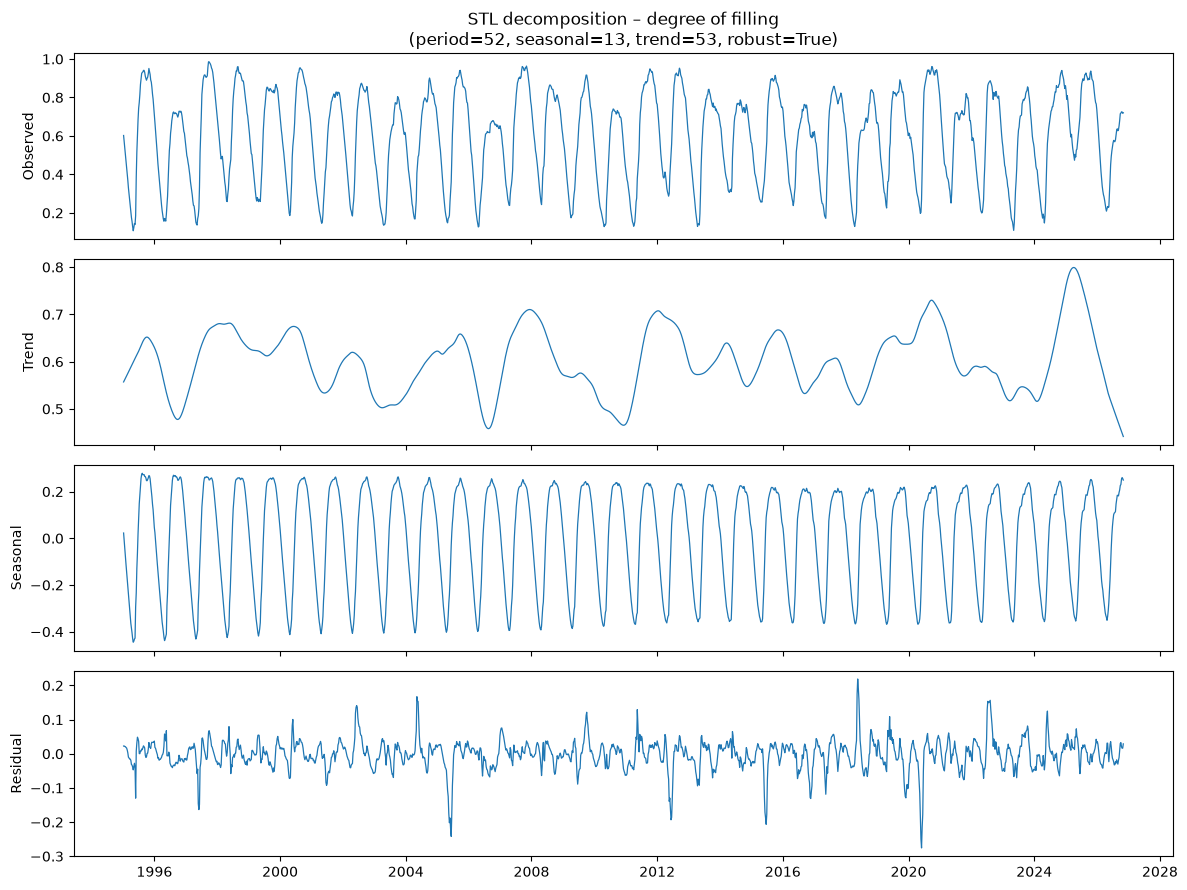

In [24]:
from statsmodels.tsa.seasonal import STL

# Apply STL decomposition to a weekly time series
def plot_stl(time_series, period=52, seasonal=13, trend=53,
             robust=True, title="STL decomposition – degree of filling"):

    # Validate smoothing parameters
    if seasonal < 3 or seasonal % 2 == 0:
        raise ValueError("seasonal must be an odd integer >= 3")

    if trend <= period or trend % 2 == 0:
        raise ValueError("trend must be an odd integer > period")

    # Perform STL decomposition
    stl_result = STL(
        time_series,
        period=period,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    ).fit()

    # Store decomposition components
    decomposition_components = [
        ("Observed", stl_result.observed),
        ("Trend", stl_result.trend),
        ("Seasonal", stl_result.seasonal),
        ("Residual", stl_result.resid)
    ]

    # Plot the decomposition
    fig, plot_axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

    for plot_axis, (component_name, component_values) in zip(
        plot_axes, decomposition_components
    ):
        plot_axis.plot(
            time_series.index,
            np.asarray(component_values),
            lw=0.9
        )
        plot_axis.set_ylabel(component_name)

    plot_axes[0].set_title(
        f"{title}\n(period={period}, seasonal={seasonal}, "
        f"trend={trend}, robust={robust})"
    )

    fig.tight_layout()
    return fig

# Apply STL decomposition to the reservoir filling level
fig = plot_stl(
    filling_level,
    period=52,
    seasonal=13,
    trend=53,
    robust=True
)

plt.show()

The STL analysis separates the weekly reservoir filling data into three parts: trend, seasonal pattern and residuals. A period of 52 weeks was used to capture the yearly pattern, and robust fitting was chosen to reduce the effect of unusual years. The seasonal component shows a clear pattern that repeats each year, with values changing by around ±0.3 compared to the trend. The trend changes more slowly and stays between approximately 0.45 and 0.8, reaching its highest level around 2025. Most residual values are small, but there are some larger differences from the usual pattern, especially around 2018 and 2020.

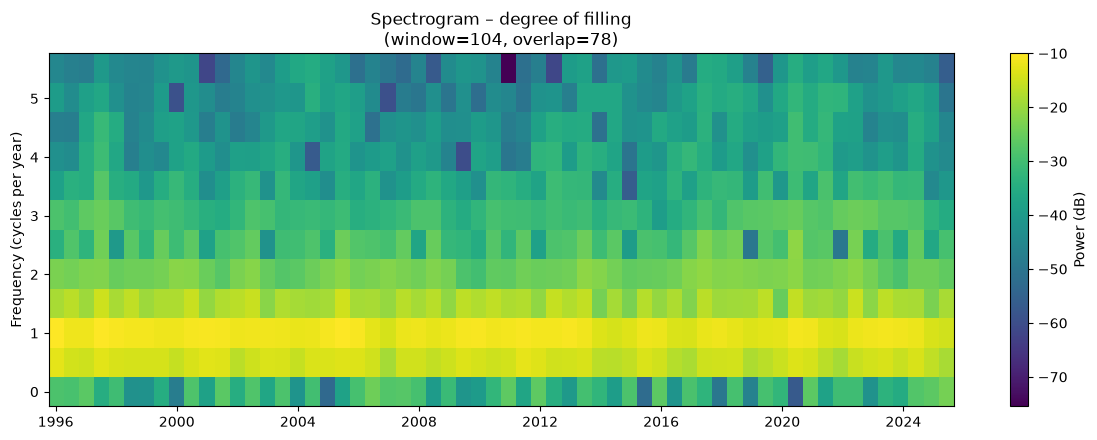

In [25]:
from scipy.signal import spectrogram

# Plot a spectrogram of a weekly time series
def plot_spectrogram(time_series, window_length=104, overlap=78,
                     samples_per_year=52.18, max_freq=6.0,
                     title="Spectrogram – degree of filling"):

    # Validate parameters
    if not 0 <= overlap < window_length:
        raise ValueError("overlap must be >= 0 and < window_length")

    if window_length > len(time_series):
        raise ValueError("window_length is longer than the time series")

    # Calculate the spectrogram
    frequencies, times, power = spectrogram(
        time_series.values.astype(float),
        fs=samples_per_year,
        window="hann",
        nperseg=window_length,
        noverlap=overlap,
        detrend="linear",
        scaling="density"
    )

    # Convert window times to dates
    dates = time_series.index[0] + pd.to_timedelta(
        times * 365.25, unit="D"
    )
    keep = frequencies <= max_freq

    # Plot power as a function of time and frequency
    fig, axis = plt.subplots(figsize=(12, 4.5))

    mesh = axis.pcolormesh(
        dates,
        frequencies[keep],
        10 * np.log10(power[keep] + 1e-12),
        shading="auto"
    )

    fig.colorbar(mesh, ax=axis, label="Power (dB)")
    axis.set_ylabel("Frequency (cycles per year)")
    axis.set_title(
        f"{title}\n(window={window_length}, overlap={overlap})"
    )

    fig.tight_layout()
    return fig


# Test the spectrogram function
fig = plot_spectrogram(filling_level)
plt.show()

The spectrogram was used to study how the frequency patterns in reservoir filling develop over time. The analysis used two-year windows (104 weeks), overlapping by 78 weeks. The results show that the yearly cycle is clearly the most important pattern and remains quite similar from 1996 to 2025. A smaller pattern can also be seen twice a year, while the other frequencies have much lower values.

## Log with a description of the work  (300–500 words)

### Notebook:
The required libraries were imported, and the NVE regions (RV, RM, RN, RØ and RS) were loaded from shapefiles and converted to coordinates. The regions were divided into four areas: East (RS + RØ), North (RM + RN), West (RV) and Mid (RM). Mid was used as an approximation for NO3, since the NVE regions do not match the price areas exactly. For each area, 1,000 random points were created inside the polygons using a fixed seed. The points were plotted to check that they were in the correct areas. The first 50 points from each area were saved as a JSON file for the Streamlit app. A function called download_weather was created to get hourly ERA5 data from Open-Meteo for eight weather variables. The locations were processed in groups of 25, and the code waits and tries again if the API limit is reached. The function was first tested with one week of data for all areas, and then used to download data for 2024 from 50 locations in Mid. The average of the locations gave 8,784 hourly observations. The dct_highpass function was used to remove seasonal changes, and SPC was used to find unusual precipitation values. With a 3σ limit, 643 outliers (7.3%) were found. The threshold test showed 1,204 outliers at 2σ and 365 at 4σ. LOF found 88 temperature anomalies (1%). Finally, weekly reservoir filling data for NO3 was downloaded from NVE. The data was analysed using STL decomposition with a period of 52 weeks and a spectrogram. The yearly cycle was the strongest signal.
### GitHub:
Updates were made on a branch called IND320_part3.  The repository was organised into the folders notebooks, pages, screencasts and archive. The functions used in both the notebook and the app were placed in data_quality.py. No CSV files were added to the repository, since the coordinates were saved in data/locations.json, which the app reads. The requirements.txt file was updated with scipy, scikit-learn and statsmodels.

### Streamlit:
Two new pages were added to the Streamlit app, both using tabs. The page 6_STL_Spectrogram.py shows the STL decomposition and spectrogram of reservoir filling. Sliders are used to adjust the smoothing settings, and the user can choose between the price areas NO1–NO5. The page 7_Outliers_Anomalies.py shows SPC outliers and LOF anomalies in the weather data. The user can choose the area, year and number of locations, and adjust the threshold, cutoff and number of neighbours. Weather data is downloaded directly from Open-Meteo for the selected area and stored using st.cache_data, so it does not need to be downloaded again every time. Each page has its own area selector. The front page, 1_Front.py, was also updated with a description of Part 3 and new links to the documentation

# KI-Erklæring
In this assignment, the AI tools ChatGPT and Claude were used in accordance with NMBU’s guidelines for the use of AI (K3). More specifically, they were employed to verify the code by checking whether it was correct and met the assignment requirements. When errors were identified, the tools provided detailed suggestions and explanations on how to rectify them. AI was primarily used to understand programming concepts, debug code, improve code structure, and explain the functionality of the applications. These suggestions were utilized to correct errors, make improvements, and gain a better understanding of the solutions.